**Import library yang dibutuhkan**

In [ ]:
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import spacy
import numpy as np

In [ ]:
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from wordcloud import WordCloud

In [ ]:
data = "/content/sample_data/preprocessed_data.csv"
df = pd.read_csv(data, header=None, names=["text"], encoding="utf-8" )

In [ ]:
pd.set_option('display.max_colwidth', None)
print(df.iloc[0]["text"])

2019 will see gadgets like gaming smartphones and wearable medical devices lifting the user experience to a whole new level mintindiawire consumer technologyconsumer technology trends in new yeartech gadgetsfoldable phonesgaming smartphoneswearable medical devicestechnology new delhi gadgets have become an integral part of our lives with most of us relying on some form of factor to communicate commute work be informed or entertained year 2019 will see some gadgets lifting the user experience to a whole new level here is what we can expect to see smartphones with foldable screens foldable phones are finally moving from the concept stage to commercial launches they are made up of organic lightemitting diode oled panels with higher plastic substrates allowing them to be bent without damage usbased display maker royole corp foldable phone flexpai has already arrived in select markets while samsung unnamed foldable phone is expected sometime next year samsung smartphone chief executive offi

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

**Named Entity Recognition (NER)**

In [ ]:
nlp = spacy.load("en_core_web_sm")

In [ ]:
def preserve_named_entities(text):
    doc = nlp(text)
    tokens = []
    for ent in doc.ents:
        if ent.label_ in ["GPE", "ORG"]:
            text = text.replace(ent.text, ent.text.replace(" ", "_"))
    return text

In [ ]:
df["text"] = df["text"].apply(preserve_named_entities)

In [ ]:
print(df.iloc[0]["text"])

2019 will see gadgets like gaming smartphones and wearable medical devices lifting the user experience to a whole new level mintindiawire consumer technologyconsumer technology trends in new yeartech gadgetsfoldable phonesgaming smartphoneswearable medical devicestechnology new_delhi gadgets have become an integral part of our lives with most of us relying on some form of factor to communicate commute work be informed or entertained year 2019 will see some gadgets lifting the user experience to a whole new level here is what we can expect to see smartphones with foldable screens foldable phones are finally moving from the concept stage to commercial launches they are made up of organic lightemitting diode oled panels with higher plastic substrates allowing them to be bent without damage usbased display maker royole_corp_foldable_phone_flexpai has already arrived in select markets while samsung unnamed foldable phone is expected sometime next year samsung smartphone chief executive offi

**Tokenisasi Kata**

In [ ]:
df["text"] = df["text"].apply(word_tokenize)

In [ ]:
print(df.iloc[0]["text"])

['2019', 'will', 'see', 'gadgets', 'like', 'gaming', 'smartphones', 'and', 'wearable', 'medical', 'devices', 'lifting', 'the', 'user', 'experience', 'to', 'a', 'whole', 'new', 'level', 'mintindiawire', 'consumer', 'technologyconsumer', 'technology', 'trends', 'in', 'new', 'yeartech', 'gadgetsfoldable', 'phonesgaming', 'smartphoneswearable', 'medical', 'devicestechnology', 'new_delhi', 'gadgets', 'have', 'become', 'an', 'integral', 'part', 'of', 'our', 'lives', 'with', 'most', 'of', 'us', 'relying', 'on', 'some', 'form', 'of', 'factor', 'to', 'communicate', 'commute', 'work', 'be', 'informed', 'or', 'entertained', 'year', '2019', 'will', 'see', 'some', 'gadgets', 'lifting', 'the', 'user', 'experience', 'to', 'a', 'whole', 'new', 'level', 'here', 'is', 'what', 'we', 'can', 'expect', 'to', 'see', 'smartphones', 'with', 'foldable', 'screens', 'foldable', 'phones', 'are', 'finally', 'moving', 'from', 'the', 'concept', 'stage', 'to', 'commercial', 'launches', 'they', 'are', 'made', 'up', 'of

**Hapus Stopwords**

In [ ]:
extra_stopwords = {'said', 'also','like','likely','would','could'}
stop_words = set(stopwords.words('english')).union(extra_stopwords)
df["text"] = df["text"].apply(lambda tokens: [word for word in tokens if word not in stop_words])

In [ ]:
print(df.iloc[0]["text"])

['2019', 'see', 'gadgets', 'gaming', 'smartphones', 'wearable', 'medical', 'devices', 'lifting', 'user', 'experience', 'whole', 'new', 'level', 'mintindiawire', 'consumer', 'technologyconsumer', 'technology', 'trends', 'new', 'yeartech', 'gadgetsfoldable', 'phonesgaming', 'smartphoneswearable', 'medical', 'devicestechnology', 'new_delhi', 'gadgets', 'become', 'integral', 'part', 'lives', 'us', 'relying', 'form', 'factor', 'communicate', 'commute', 'work', 'informed', 'entertained', 'year', '2019', 'see', 'gadgets', 'lifting', 'user', 'experience', 'whole', 'new', 'level', 'expect', 'see', 'smartphones', 'foldable', 'screens', 'foldable', 'phones', 'finally', 'moving', 'concept', 'stage', 'commercial', 'launches', 'made', 'organic', 'lightemitting', 'diode', 'oled', 'panels', 'higher', 'plastic', 'substrates', 'allowing', 'bent', 'without', 'damage', 'usbased', 'display', 'maker', 'royole_corp_foldable_phone_flexpai', 'already', 'arrived', 'select', 'markets', 'samsung', 'unnamed', 'fol

**Lemmatization**

In [ ]:
lemmatizer = WordNetLemmatizer()
df["text"] = df["text"].apply(lambda tokens: [lemmatizer.lemmatize(word) for word in tokens])

In [ ]:
print(df.iloc[0]["text"])

['2019', 'see', 'gadget', 'gaming', 'smartphones', 'wearable', 'medical', 'device', 'lifting', 'user', 'experience', 'whole', 'new', 'level', 'mintindiawire', 'consumer', 'technologyconsumer', 'technology', 'trend', 'new', 'yeartech', 'gadgetsfoldable', 'phonesgaming', 'smartphoneswearable', 'medical', 'devicestechnology', 'new_delhi', 'gadget', 'become', 'integral', 'part', 'life', 'u', 'relying', 'form', 'factor', 'communicate', 'commute', 'work', 'informed', 'entertained', 'year', '2019', 'see', 'gadget', 'lifting', 'user', 'experience', 'whole', 'new', 'level', 'expect', 'see', 'smartphones', 'foldable', 'screen', 'foldable', 'phone', 'finally', 'moving', 'concept', 'stage', 'commercial', 'launch', 'made', 'organic', 'lightemitting', 'diode', 'oled', 'panel', 'higher', 'plastic', 'substrate', 'allowing', 'bent', 'without', 'damage', 'usbased', 'display', 'maker', 'royole_corp_foldable_phone_flexpai', 'already', 'arrived', 'select', 'market', 'samsung', 'unnamed', 'foldable', 'phone

Hapus Digit

In [ ]:
df["text"] = df["text"].apply(lambda tokens: [word for word in tokens if not (word.isdigit() or word.replace('.', '').isnumeric() or word.replace(',', '').isnumeric())])

In [ ]:
print(df.iloc[0]["text"])

['see', 'gadget', 'gaming', 'smartphones', 'wearable', 'medical', 'device', 'lifting', 'user', 'experience', 'whole', 'new', 'level', 'mintindiawire', 'consumer', 'technologyconsumer', 'technology', 'trend', 'new', 'yeartech', 'gadgetsfoldable', 'phonesgaming', 'smartphoneswearable', 'medical', 'devicestechnology', 'new_delhi', 'gadget', 'become', 'integral', 'part', 'life', 'u', 'relying', 'form', 'factor', 'communicate', 'commute', 'work', 'informed', 'entertained', 'year', 'see', 'gadget', 'lifting', 'user', 'experience', 'whole', 'new', 'level', 'expect', 'see', 'smartphones', 'foldable', 'screen', 'foldable', 'phone', 'finally', 'moving', 'concept', 'stage', 'commercial', 'launch', 'made', 'organic', 'lightemitting', 'diode', 'oled', 'panel', 'higher', 'plastic', 'substrate', 'allowing', 'bent', 'without', 'damage', 'usbased', 'display', 'maker', 'royole_corp_foldable_phone_flexpai', 'already', 'arrived', 'select', 'market', 'samsung', 'unnamed', 'foldable', 'phone', 'expected', '

Sambung Kembali

In [ ]:
df["text"] = df["text"].apply(lambda tokens: ' '.join(tokens))

In [ ]:
print(df.iloc[0]["text"])

see gadget gaming smartphones wearable medical device lifting user experience whole new level mintindiawire consumer technologyconsumer technology trend new yeartech gadgetsfoldable phonesgaming smartphoneswearable medical devicestechnology new_delhi gadget become integral part life u relying form factor communicate commute work informed entertained year see gadget lifting user experience whole new level expect see smartphones foldable screen foldable phone finally moving concept stage commercial launch made organic lightemitting diode oled panel higher plastic substrate allowing bent without damage usbased display maker royole_corp_foldable_phone_flexpai already arrived select market samsung unnamed foldable phone expected sometime next year samsung smartphone chief executive officer dj koh make million unit lg expected display foldable phone next year meanwhile apple nokia lenovo huawei working foldable phone reportedly esim soon smartphone need physical sim card anymore esim technol

**TF-IDF**

In [ ]:
vectorizer = TfidfVectorizer()

In [ ]:
tfidf_matrix = vectorizer.fit_transform(df["text"])

**Reduksi Dimensi dengan Truncated SVD**

In [ ]:
svd = TruncatedSVD(n_components=50, random_state=42)
reduced_matrix = svd.fit_transform(tfidf_matrix)

In [ ]:
silhouette_scores = []
max_clusters = 10

In [ ]:
for i in range(2, max_clusters + 1):
    kmeans = KMeans(n_clusters=i, random_state=40, n_init=10)
    kmeans.fit(reduced_matrix)
    score = silhouette_score(reduced_matrix, kmeans.labels_)
    silhouette_scores.append(score)
    print(f"Cluster: {i}, Silhouette Score: {score:.4f}")

Cluster: 2, Silhouette Score: 0.2605
Cluster: 3, Silhouette Score: 0.2718
Cluster: 4, Silhouette Score: 0.1144
Cluster: 5, Silhouette Score: 0.0284
Cluster: 6, Silhouette Score: 0.1251
Cluster: 7, Silhouette Score: 0.0627
Cluster: 8, Silhouette Score: 0.1190
Cluster: 9, Silhouette Score: 0.0496
Cluster: 10, Silhouette Score: 0.0560


**Visualisasi Silhouette Score**

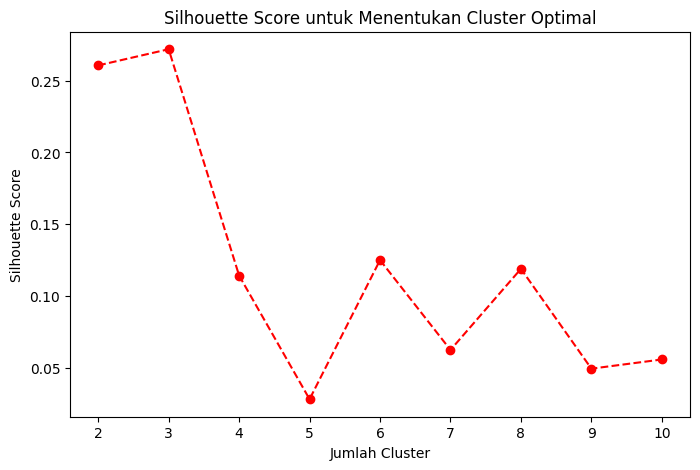

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(2, max_clusters + 1), silhouette_scores, marker='o', linestyle='--', color='r')
plt.xlabel("Jumlah Cluster")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score untuk Menentukan Cluster Optimal")
plt.show()

In [ ]:
optimal_clusters = np.argmax(silhouette_scores) + 2
print(f"\nOptimal number of clusters : {optimal_clusters}")


Optimal number of clusters : 3


karena Silhouette Score tertinggi berada di cluster 3, maka optimal clusternya : **3**

**KMeans Clustering dengan Cluster Optimal**

In [ ]:
kmeans_optimal = KMeans(n_clusters=optimal_clusters, random_state=42, n_init=10)
cluster_labels = kmeans_optimal.fit_predict(reduced_matrix)

**Reduksi Dimensi ke 2D dengan t-SNE**

In [ ]:
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(reduced_matrix)

**Visualisasi Hasil Clustering ke 2D**

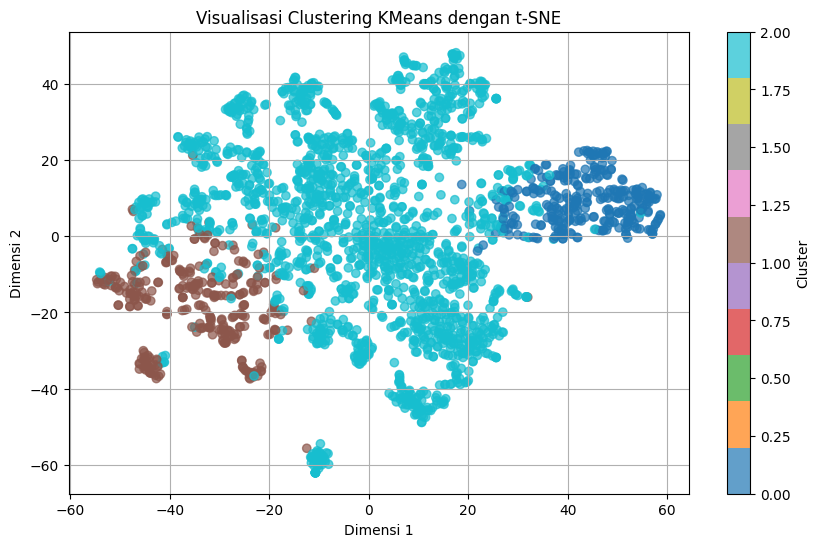

In [ ]:
plt.figure(figsize=(10, 6))
scatter = plt.scatter(tsne_result[:, 0], tsne_result[:, 1], c=cluster_labels, cmap='tab10', alpha=0.7)
plt.title("Visualisasi Clustering KMeans dengan t-SNE")
plt.xlabel("Dimensi 1")
plt.ylabel("Dimensi 2")
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

**Kata Terbanyak Tiap Cluster**

In [ ]:
df["cluster"] = cluster_labels

for i in range(optimal_clusters):
    print(f"\nCluster {i}:")
    cluster_text = df[df["cluster"] == i]["text"]
    joined_text = ' '.join(cluster_text)
    tokens = word_tokenize(joined_text)
    freq_dist = nltk.FreqDist(tokens)
    print(freq_dist.most_common(20))


Cluster 0:
[('bjp', 369), ('party', 366), ('congress', 359), ('election', 357), ('seat', 267), ('state', 257), ('minister', 225), ('modi', 215), ('leader', 187), ('lok_sabha', 159), ('poll', 139), ('chief', 132), ('government', 113), ('people', 106), ('voter', 106), ('prime', 104), ('vote', 100), ('political', 100), ('pradesh', 99), ('alliance', 98)]

Cluster 1:
[('smartphone', 336), ('camera', 292), ('pro', 269), ('display', 232), ('samsung', 220), ('phone', 219), ('note', 219), ('galaxy', 213), ('oneplus', 206), ('redmi', 201), ('variant', 148), ('smartphones', 146), ('realme', 126), ('india', 125), ('device', 121), ('new', 120), ('storage', 115), ('come', 113), ('xiaomi', 113), ('screen', 108)]

Cluster 2:
[('company', 551), ('year', 513), ('user', 491), ('india', 461), ('new', 435), ('film', 413), ('one', 391), ('data', 367), ('people', 355), ('technology', 329), ('time', 321), ('apple', 319), ('app', 304), ('market', 300), ('u', 287), ('google', 280), ('service', 251), ('first', 

**Visualisasi Word Clouds Tiap Cluster**

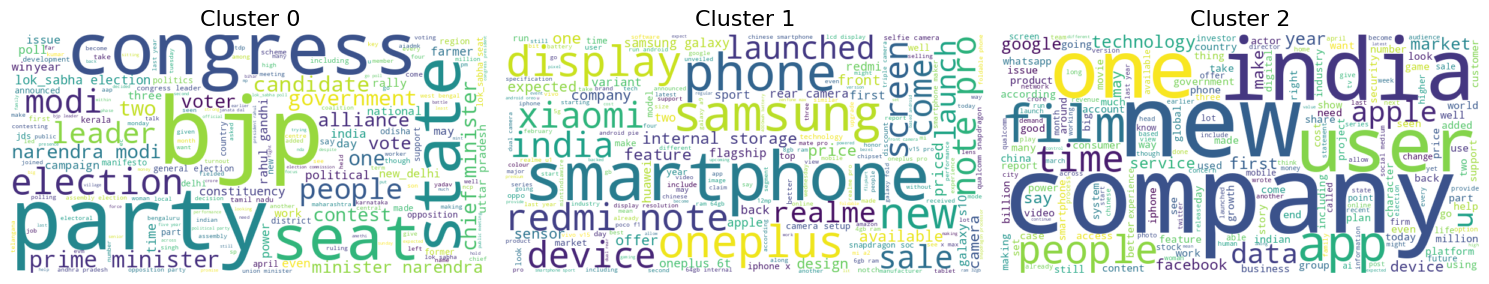

In [ ]:
selected_clusters = [0, 1, 2]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 6))

for idx, cluster_id in enumerate(selected_clusters):
    cluster_text = ' '.join(df[df["cluster"] == cluster_id]["text"])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(cluster_text)
    axes[idx].imshow(wordcloud, interpolation='bilinear')
    axes[idx].set_title(f"Cluster {cluster_id}", fontsize=16)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()


Print Detail Tiap Cluster

In [ ]:
df['original_index'] = df.index
df['processed_text'] = df['text']

print("\nCluster Details:")
cluster_counts = df['cluster'].value_counts().sort_index()

for cluster_id, count in cluster_counts.items():
    print(f"\nCluster {cluster_id}:")
    print(f"Number of texts in cluster: {count}")

    sample_texts = df[df['cluster'] == cluster_id]['processed_text'].tolist()[:3]
    sample_indices = df[df['cluster'] == cluster_id]['original_index'].tolist()[:3]

    print("Sample texts from this cluster:")
    for text, index in zip(sample_texts, sample_indices):
        print(f"- Index: {index}, Text: {text}")



Cluster Details:

Cluster 0:
Number of texts in cluster: 302
Sample texts from this cluster:
- Index: 9, Text: ncp leadership tremendous pressure consider fielding thirdgeneration pawars key constituency western maharashtra parth pawar open keenness contest maval lok_sabha constituency near pune rohit pawar son sharad pawar brother rajendra pawar keen entering electoral arena set eye karjatjamkhed assembly constituency ahmednagar constituency pressure increased sharad pawar contest madha sule seek reelection baramati last month sharad pawar sought end speculation saying thirdgeneration pawar contest lok_sabha poll however ncp leader legislator say parth pawar rohit pawar ready wait pawar intervened maval constituency saw poster parth pawar coming several place known ambitious two thirdgeneration ticket aspirant parth started touring constituency six month back one ncp legislator keen get active politics dedicated band young worker confident win maval seat time ncp legislator requestin

**Kesimpulan**

Cluster 0 berisi kategori berita politik dan pemerintahan, terutama pemilu dan dinamika antar partai.

Cluster 1 berisi kategori berita gadget, seperti spesifikasi, review, dan peluncuran gadget.

Cluster 2 berisi kategori berita teknologi yang umum seperti big tech, sosial media, serta entertaiment seperti film.